# Alice EEG · entrenamiento GRU + CTC en Colab

Adapta la GRU de T12 al EEG de 27 participantes de Alice. Usa cinco GRU de 512 unidades, un adaptador de entrada por participante y un decodificador compartido. Los pesos se entrenan desde cero con lote efectivo 64 y microlotes de 16.

Descarga unos 2,47 GB de EEG y anotaciones y prepara los datos por participante. Train usa los tramos 1–8, validación 9–10 y test 11–12 de los mismos participantes. Los cuatro participantes restantes quedan excluidos por anotaciones incompletas o marcas temporales duplicadas.

El perfil usa CUDA, hasta 10.001 actualizaciones y un límite de 3.600 segundos de bucle. Las fuentes, la configuración, los registros y los pesos se guardan en Drive.


In [17]:
#@title 1. Comprobar Colab con GPU
from pathlib import Path
import os
import subprocess
import sys
try:
    import google.colab
except ImportError as error:
    raise RuntimeError('Conecta el notebook a una VM de Colab con T4, también si usas VS Code.') from error
COLAB_BASE = globals().get('COLAB_BASE', Path.cwd().resolve())
PROJECT = COLAB_BASE / 'tic_alice_colab'
try:
    subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv'], check=True)
except (FileNotFoundError, subprocess.CalledProcessError) as error:
    raise RuntimeError('Selecciona GPU T4 en el entorno de Colab y vuelve a ejecutar.') from error
print('Proyecto Alice:', PROJECT)
print('Este perfil requiere CUDA; el entrenamiento no cambia automáticamente a CPU.')

Proyecto Alice: /content/tic_alice_colab
Este perfil requiere CUDA; el entrenamiento no cambia automáticamente a CPU.


In [18]:
#@title 2. Copiar el código del proyecto (snapshot incluido)
import base64
import hashlib
import io
import json
from pathlib import PurePosixPath
from zipfile import ZipFile

SOURCE_SHA256 = '6a5df1b73faf72cf31272f060aeb3d28db8e28d027f7c0920ac0c0e5736ae6f0'
SOURCE_B64 = (
    '...'
)

SOURCE_BYTES = base64.b64decode(SOURCE_B64)
if hashlib.sha256(SOURCE_BYTES).hexdigest() != SOURCE_SHA256:
    raise ValueError("El paquete de código no supera su SHA-256.")
PROJECT.mkdir(parents=True, exist_ok=True)
with ZipFile(io.BytesIO(SOURCE_BYTES)) as archive:
    for member in archive.infolist():
        relative = PurePosixPath(member.filename)
        if relative.is_absolute() or ".." in relative.parts or member.is_dir():
            raise ValueError(f"Ruta inesperada en el paquete: {member.filename}")
        destination = PROJECT.joinpath(*relative.parts)
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(member))
SOURCE_MANIFEST = json.loads((PROJECT / "source_snapshot.json").read_text())
for name, expected in SOURCE_MANIFEST["files"].items():
    if hashlib.sha256((PROJECT / name).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Código distinto del snapshot: {name}")
print("Código preparado:", len(SOURCE_MANIFEST["files"]), "archivos")
print("Commit base:", SOURCE_MANIFEST["git_commit_base"])
print("SHA-256 del paquete:", SOURCE_SHA256)


Código preparado: 38 archivos
Commit base: d0a3c131563bb805d4159218fe8b195f3c0d47c8
SHA-256 del paquete: 6a5df1b73faf72cf31272f060aeb3d28db8e28d027f7c0920ac0c0e5736ae6f0


In [19]:
#@title 3. Reutilizar el entorno anterior o preparar uno aislado
import shutil
from collections import deque
from contextlib import nullcontext
import signal

# Solo se reutiliza el entorno de T12 si coinciden las dependencias; no se modifica.
candidate = COLAB_BASE / 'tic_proyecto_colab' / '.venv' / 'bin' / 'python'
probe = """
from importlib.metadata import version
import json, torch
expected = {'torch':'2.5.1','numpy':'2.1.3','scipy':'1.14.1','pyyaml':'6.0.2','wandb':'0.18.7','matplotlib':'3.9.3','g2p-en':'2.1.0','nltk':'3.9.2'}
assert all(version(k).split('+')[0] == v for k, v in expected.items()), 'Versiones incompatibles'
assert torch.cuda.is_available(), 'CUDA no está disponible en este Python'
major, minor = torch.cuda.get_device_capability()
assert f'sm_{major}{minor}' in torch.cuda.get_arch_list(), 'GPU no soportada por este Torch fijado'
print(json.dumps({'gpu':torch.cuda.get_device_name(), 'cuda':torch.version.cuda,
                  'cudnn':torch.backends.cudnn.version(), 'memoria_mib':torch.cuda.get_device_properties(0).total_memory/2**20,
                  'paquetes':{k:version(k) for k in expected}}))
"""
candidates = [candidate, PROJECT / '.venv_cuda' / 'bin' / 'python']
PYTHON = None
for candidate_env in candidates:
    if candidate_env.is_file() and subprocess.run([str(candidate_env), '-c', probe], capture_output=True).returncode == 0:
        PYTHON = candidate_env
        break
if PYTHON is not None:
    print('Entorno CUDA compatible; no se reinstala ni modifica:', PYTHON)
else:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', 'uv==0.9.4'], check=True)
    uv = shutil.which('uv')
    if uv is None:
        raise RuntimeError('No se encontró uv.')
    PYTHON = PROJECT / '.venv_cuda' / 'bin' / 'python'
    if not PYTHON.is_file():
        subprocess.run([uv, 'venv', '--python', '3.12.11', '--seed', str(PROJECT / '.venv_cuda')], check=True)
    subprocess.run([uv, 'pip', 'install', '--python', str(PYTHON), '--index-url', 'https://download.pytorch.org/whl/cu124', 'torch==2.5.1'], check=True)
    subprocess.run([uv, 'pip', 'install', '--python', str(PYTHON), '-r', 'requirements-alice.txt'], cwd=PROJECT, check=True)
    subprocess.run([uv, 'pip', 'check', '--python', str(PYTHON)], check=True)
CUDA_PROBE = subprocess.check_output([str(PYTHON), '-c', probe], text=True)
print(CUDA_PROBE)
for name in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ[name] = '2'

def ejecutar(argumentos: list[str], log: Path | None = None) -> None:
    """Muestra stdout/stderr, conserva log y detiene el proceso al interrumpir."""
    recent = deque(maxlen=25)
    process = subprocess.Popen([str(PYTHON), *argumentos], cwd=PROJECT,
                               env={**os.environ, 'MPLBACKEND': 'Agg'}, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace', bufsize=1)
    try:
        with (log.open('w', encoding='utf-8') if log else nullcontext(None)) as stream:
            for line in process.stdout:
                print(line, end='', flush=True)
                recent.append(line)
                if stream:
                    stream.write(line)
                    stream.flush()
        returncode = process.wait()
    finally:
        if process.poll() is None:
            process.send_signal(signal.SIGINT)
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        process.stdout.close()
    if returncode:
        raise RuntimeError('Falló el comando: ' + ' '.join(argumentos) + '\n' + ''.join(recent))
print('Entorno preparado. No hay que reiniciar el kernel.')

Entorno CUDA compatible; no se reinstala ni modifica: /content/tic_alice_colab/.venv_cuda/bin/python
{"gpu": "Tesla T4", "cuda": "12.4", "cudnn": 90100, "memoria_mib": 14912.6875, "paquetes": {"torch": "2.5.1+cu124", "numpy": "2.1.3", "scipy": "1.14.1", "pyyaml": "6.0.2", "wandb": "0.18.7", "matplotlib": "3.9.3", "g2p-en": "2.1.0", "nltk": "3.9.2"}}

Entorno preparado. No hay que reiniciar el kernel.


In [20]:
#@title 4. Guardar este experimento en Drive
from datetime import datetime
from uuid import uuid4
from zoneinfo import ZoneInfo
from google.colab import drive
CARPETA_DRIVE = 'speech_bci' #@param {type:"string"}
relative = Path(CARPETA_DRIVE)
if not CARPETA_DRIVE.strip() or relative.is_absolute() or '..' in relative.parts:
    raise ValueError('Indica una carpeta relativa a Mi unidad.')
DRIVE_MOUNT = COLAB_BASE / 'drive'
drive.mount(str(DRIVE_MOUNT))
DRIVE_ROOT = DRIVE_MOUNT / 'MyDrive' / relative
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
link = PROJECT / 'runs' / 'drive_alice'
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink():
    if link.resolve() != DRIVE_ROOT.resolve():
        raise RuntimeError('La carpeta de Drive difiere de la usada antes; utiliza una sesión nueva.')
elif link.exists():
    raise RuntimeError('Ya existe runs/drive_alice y no es el enlace esperado.')
else:
    link.symlink_to(DRIVE_ROOT, target_is_directory=True)
EXPERIMENT_ID = 'alice_t4_' + datetime.now(ZoneInfo('Europe/Madrid')).strftime('%Y%m%d_%H%M%S') + '_' + uuid4().hex[:8]
RESULTS = DRIVE_ROOT / 'experimentos' / EXPERIMENT_ID
RESULTS.mkdir(parents=True, exist_ok=False)
CONFIG = 'configs/alice_ctc_t4_ejecucion.yaml'
config_code = """
import sys
from pathlib import Path
import yaml
cfg = yaml.safe_load(Path('configs/alice_ctc_t4.yaml').read_text())
base = Path('runs/drive_alice/experimentos') / sys.argv[1]
cfg['salida']['directorio'] = str(base / 'resultados')
cfg['wandb']['directorio'] = str(base / 'tracking')
Path(sys.argv[2]).write_text(yaml.safe_dump(cfg, sort_keys=False))
"""
subprocess.run([str(PYTHON), '-c', config_code, EXPERIMENT_ID, CONFIG], cwd=PROJECT, check=True)
(RESULTS / 'fuentes.zip').write_bytes(SOURCE_BYTES)
(RESULTS / 'source_snapshot.json').write_text(json.dumps(SOURCE_MANIFEST, indent=2))
shutil.copyfile(PROJECT / CONFIG, RESULTS / 'config.yaml')
print('Resultados y checkpoints:', RESULTS)
print('W&B: proyecto tiiac-2026, modo online.')
(RESULTS / 'entorno_cuda.json').write_text(CUDA_PROBE)
print('Perfil CUDA: 27 participantes, cinco GRU de 512, lote 64 / microlote 16, máximo 1 h de bucle.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados y checkpoints: /content/drive/MyDrive/speech_bci/experimentos/alice_t4_20261021_165815_c1beed9d
W&B: proyecto tiiac-2026, modo online.
Perfil CUDA: 27 participantes, cinco GRU de 512, lote 64 / microlote 16, máximo 1 h de bucle.


In [21]:
#@title 5. Descargar los 27 participantes (2,47 GB) y preparar las señales
# No requiere los datos T12; solo reutiliza sus recursos públicos de pronunciación.
ejecutar(['scripts/get_alice.py', '--catalogo', 'docs/datasets/alice_eeg/catalogo_ctc_t4.json'], RESULTS / 'descarga.log')
ejecutar(['scripts/get_phoneme_resources.py', '--config', CONFIG], RESULTS / 'recursos.log')
ejecutar(['scripts/prepare_alice_ctc.py', '--config', CONFIG], RESULTS / 'preparacion.log')

Verificado: README.md
Verificado: dataset_description.json
Verificado: participants.json
Verificado: participants.tsv
Verificado: task-alicelistening_events.json
Verificado: sourcedata/AliceChapterOne-EEG.csv
Verificado: sub-001/eeg/sub-001_task-alicelistening_channels.tsv
Verificado: sub-001/eeg/sub-001_task-alicelistening_eeg.eeg
Verificado: sub-001/eeg/sub-001_task-alicelistening_eeg.json
Verificado: sub-001/eeg/sub-001_task-alicelistening_eeg.vhdr
Verificado: sub-001/eeg/sub-001_task-alicelistening_eeg.vmrk
Verificado: sub-001/eeg/sub-001_task-alicelistening_events.tsv
Verificado: sub-003/eeg/sub-003_task-alicelistening_channels.tsv
Verificado: sub-003/eeg/sub-003_task-alicelistening_eeg.eeg
Verificado: sub-003/eeg/sub-003_task-alicelistening_eeg.json
Verificado: sub-003/eeg/sub-003_task-alicelistening_eeg.vhdr
Verificado: sub-003/eeg/sub-003_task-alicelistening_eeg.vmrk
Verificado: sub-003/eeg/sub-003_task-alicelistening_events.tsv
Verificado: sub-005/eeg/sub-005_task-alicelisteni

## Conectar W&B

La autenticación utiliza `WANDB_API_KEY` del entorno, Secretos de Colab o una entrada oculta.


In [22]:
# #@title 6. Credencial de W&B
# import getpass
# USAR_SECRETOS_COLAB = False #@param {type:"boolean"}
# api_key = os.environ.get('WANDB_API_KEY')
# if not api_key and USAR_SECRETOS_COLAB:
#     from google.colab import userdata
#     api_key = userdata.get('WANDB_API_KEY')
# if not api_key:
#     api_key = getpass.getpass('API key de W&B (entrada oculta): ')
# if not api_key or not api_key.strip():
#     raise ValueError('Falta WANDB_API_KEY.')
# os.environ['WANDB_API_KEY'] = api_key.strip()
# os.environ['WANDB_MODE'] = 'online'
# del api_key
# print('Credencial preparada; la conexión se realiza al abrir el run.')

In [23]:
#@title 7. Entrenar, evaluar y verificar la recarga sin entrenar otra vez
import math
if not os.environ.get('WANDB_API_KEY'):
    raise RuntimeError('Ejecuta la celda de credencial.')
before = set((RESULTS / 'resultados').glob('*/resultado.json'))
ejecutar(['run.py', '--config', CONFIG], RESULTS / 'entrenamiento.log')
after = set((RESULTS / 'resultados').glob('*/resultado.json')) - before
if len(after) != 1:
    raise RuntimeError('No se identifica un único resultado nuevo. Revisa el log guardado.')
RUN_DIR = next(iter(after)).parent
report = json.loads((RUN_DIR / 'resultado.json').read_text())
checkpoint = PROJECT / report['checkpoint']
EVAL_CONFIG = 'configs/alice_ctc_t4_reevaluacion.yaml'
code = """
from pathlib import Path
import sys, yaml
cfg = yaml.safe_load(Path(sys.argv[1]).read_text())
cfg['experimento']['nombre'] += '_recarga'
Path(sys.argv[2]).write_text(yaml.safe_dump(cfg, sort_keys=False))
"""
subprocess.run([str(PYTHON), '-c', code, CONFIG, EVAL_CONFIG], cwd=PROJECT, check=True)
before_eval = set((RESULTS / 'resultados').glob('*/resultado.json'))
ejecutar(['run.py', '--config', EVAL_CONFIG, '--solo-evaluar', '--checkpoint', str(checkpoint)], RESULTS / 'recarga.log')
evaluations = set((RESULTS / 'resultados').glob('*/resultado.json')) - before_eval
if len(evaluations) != 1:
    raise RuntimeError('No se identifica la reevaluación.')
reevaluated = json.loads(next(iter(evaluations)).read_text())
assert reevaluated['evaluation_only'] and reevaluated['completed_steps'] == 0
assert report['test']['per'] == reevaluated['test']['per']
assert math.isclose(report['test']['ctc_loss'], reevaluated['test']['ctc_loss'], rel_tol=1e-5, abs_tol=1e-4)
print('Entrenamiento y recarga comprobados:', RUN_DIR)

wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/drive_alice/experimentos/alice_t4_20261021_165815_c1beed9d/tracking/wandb/run-20261021_150258-5xzfrm2b
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run alice_ctc_27s_t4_gru512
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/5xzfrm2b
Alice CTC · SpeechGRU reutilizada · Tesla T4 · secuencias {'train': 5022, 'val': 1188, 'test': 918}
Participantes: 27 · parámetros: 7,950,893
EEG 60 canales; blank=40; normalización por participante con train
paso 1/10001 · CTC=227.3129 · lr=0.020000 · CUDA pico=385 MiB asignados / 422 MiB reservados
val: PER=94.72% · CTC=237.9224
paso 100/10001 · CTC=90.9254 ·

RuntimeError: Falló el comando: scripts/report_alice_ctc.py --run-dir /content/drive/MyDrive/speech_bci/experimentos/alice_t4_20261021_165815_c1beed9d/resultados/5xzfrm2b
Traceback (most recent call last):
  File "/content/tic_alice_colab/scripts/report_alice_ctc.py", line 12, in <module>
    import matplotlib
  File "/content/tic_alice_colab/.venv_cuda/lib/python3.12/site-packages/matplotlib/__init__.py", line 1273, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
    ~~~~~~~~^^^^^^^^^^^
  File "/content/tic_alice_colab/.venv_cuda/lib/python3.12/site-packages/matplotlib/__init__.py", line 741, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from None
ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cair

/content/drive/MyDrive/speech_bci/experimentos/alice_t4_20261021_165815_c1beed9d/resultados/5xzfrm2b/comparacion_ctc.png
GPU: Tesla T4 | participantes: 27
Pasos completados: 10001 | mejor val: 2250
Bucle con validación y guardados (s): 3013.249237748
PER en test: 73.51%
PER sin señal EEG: 73.72%
PER del prior de fonemas de train: 77.29%
Referencias de test: 918 | fonemas: 28539
PER macro por participante: 73.51%
Picos CUDA (MiB): {'cuda/pico_asignado_mib': 452.068359375, 'cuda/pico_reservado_mib': 520.0}


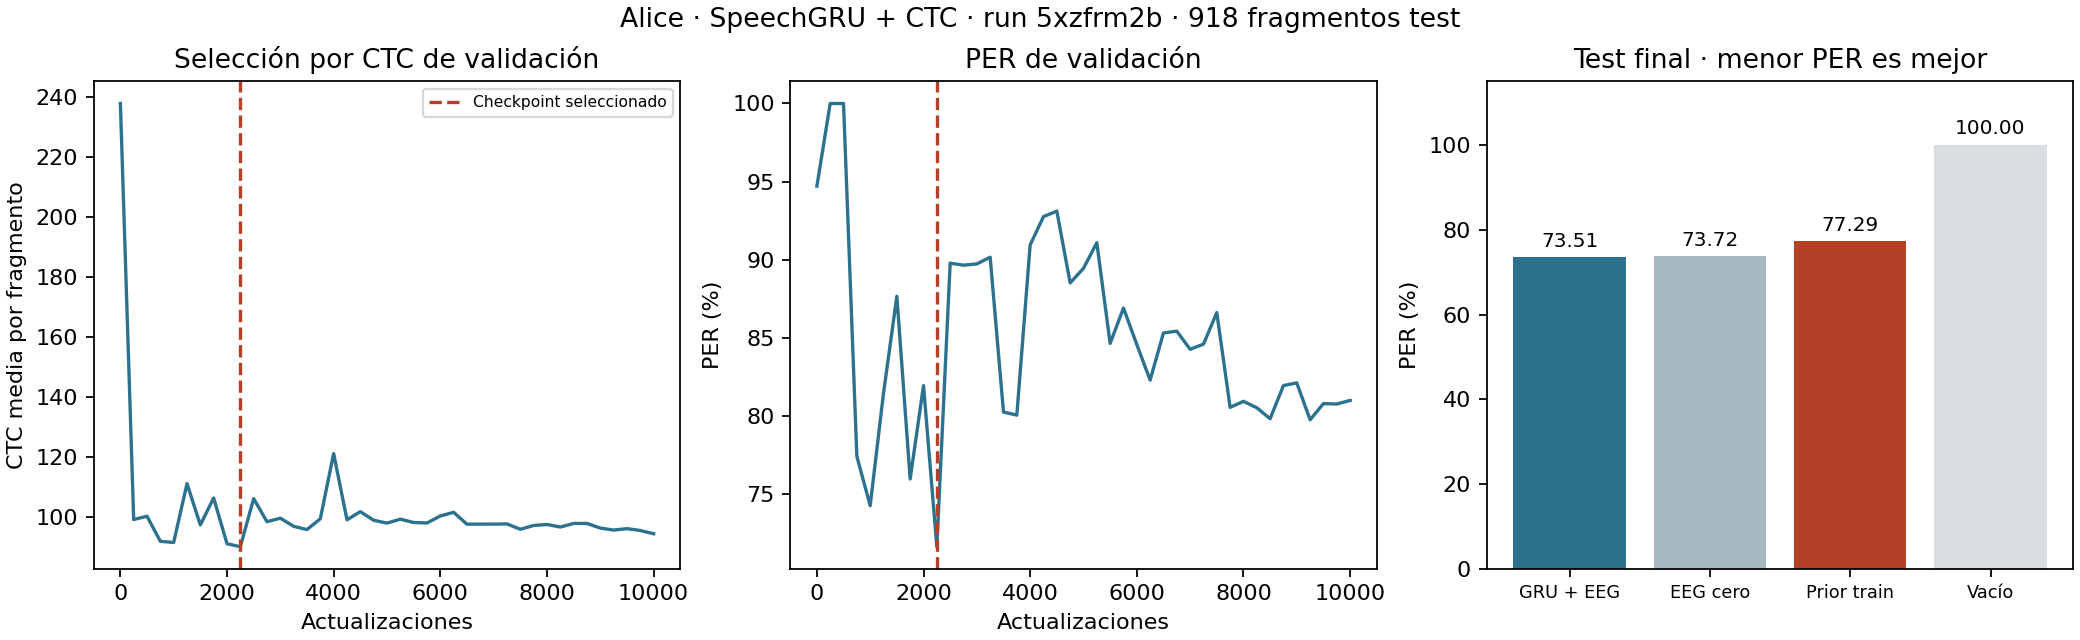

In [25]:
#@title 8. Mostrar resultados guardados (no entrena)
from IPython.display import Image, display
# Solo genera la figura desde los resultados guardados; no vuelve a entrenar.
os.environ['MPLBACKEND'] = 'Agg'
ejecutar(['scripts/report_alice_ctc.py', '--run-dir', str(RUN_DIR)], RESULTS / 'figura.log')
report = json.loads((RUN_DIR / 'resultado.json').read_text())
print('GPU:', report['hardware'], '| participantes:', len(report['subjects']))
print('Pasos completados:', report['completed_steps'], '| mejor val:', report['best_val_step'])
print('Bucle con validación y guardados (s):', report['training_seconds_including_val_and_saves'])
print('PER en test:', f"{report['test']['per']:.2%}")
print('PER sin señal EEG:', f"{report['zero_eeg_control']['per']:.2%}")
print('PER del prior de fonemas de train:', f"{report['phone_prior_control']['per']:.2%}")
print('Referencias de test:', report['test']['frases'], '| fonemas:', report['test']['fonemas'])
print('PER macro por participante:', f"{report['test_macro_per']:.2%}")
print('Picos CUDA (MiB):', report['cuda_memory'])
display(Image(filename=str(RUN_DIR / 'comparacion_ctc.png')))

## Preparación y evaluación

La normalización se ajusta con train de cada participante. Cada lote contiene fragmentos de un participante y utiliza su adaptador de entrada. Los tiempos de las palabras delimitan los fragmentos; las etiquetas son fonemas generados desde el texto con g2p-en. CTC trabaja sin alineación temporal de fonemas y SIL conserva el uso del pipeline de T12.

El checkpoint se selecciona por CTC de validación. Los registros incluyen los pasos completados, el tiempo y el PER agregado, macro y por participante. La recarga evalúa los pesos sin actualizarlos. Esta versión no guarda el estado del optimizador para reanudar.

Fuentes: [Alice EEG en NEMAR](https://www.nemar.org/dataset/nm000180) y [artículo del dataset](https://doi.org/10.1371/journal.pone.0207741).
